## Image Visualization in Pytorch tensors

In [9]:
import torch
import matplotlib.pyplot as plt
from torchvision import transforms
from PIL import Image

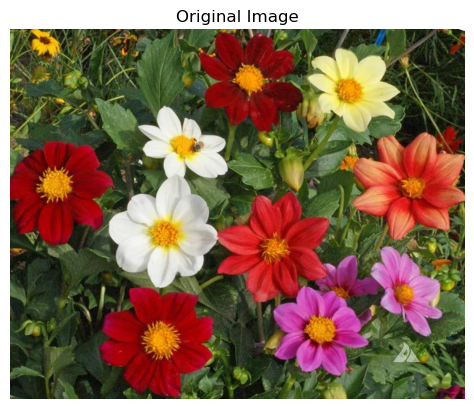

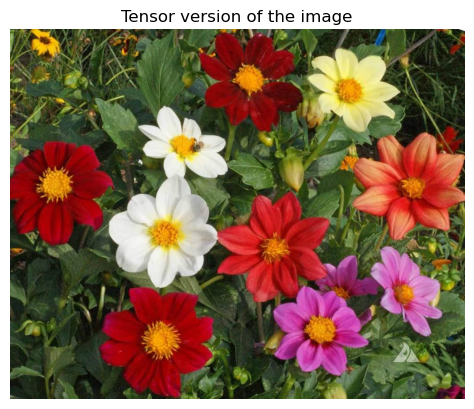

In [10]:
image_path = 'flower.jpg'
image = Image.open(image_path)

plt.imshow(image)
plt.title('Original Image')
plt.axis('off')
plt.show()

image_transform = transforms.ToTensor()
tensor_image=image_transform(image)

plt.imshow(tensor_image.permute(1,2,0))
plt.title('Tensor version of the image')
plt.axis('off')
plt.show()

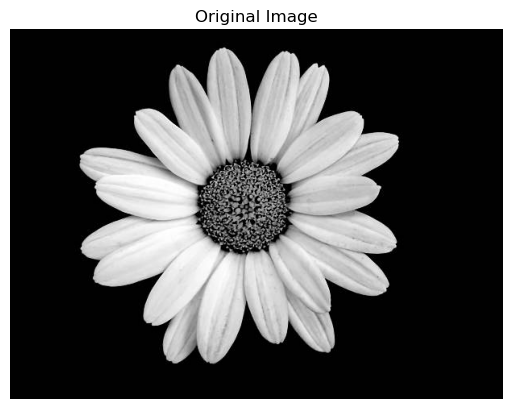

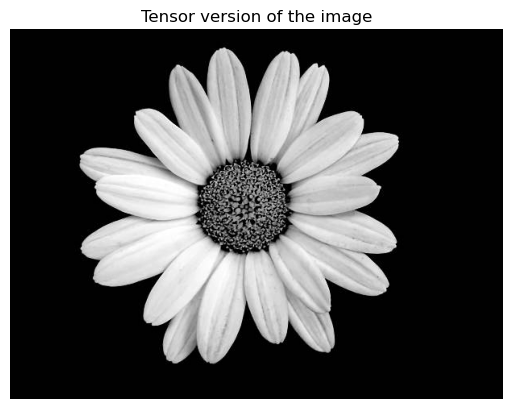

In [11]:
image_path = 'grey.jpg'
image = Image.open(image_path)

plt.imshow(image,cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

image_transform = transforms.ToTensor()
tensor_image=image_transform(image)

plt.imshow(tensor_image[0],cmap='gray')
plt.title('Tensor version of the image')
plt.axis('off')
plt.show()

## Simple Neural Network

In [12]:
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader,Dataset
from torchvision.datasets import ImageFolder
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
import matplotlib.pyplot as plt

torch.manual_seed(10)

In [13]:
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN,self).__init__()
        self.fc1=nn.Linear(3*256*256,128)
        self.relu=nn.ReLU()
        self.fc2=nn.Linear(128,2)
        self.softmax=nn.Softmax(dim=1)
    def forward(self,x):
        x=x.view(-1,3*256*256)
        x=self.relu(self.fc1(x))
        x=self.softmax(self.fc2(x))
        return x

In [14]:
transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

In [15]:
class CustomDataset(Dataset):
    def __init__(self,root,transform=None):
        self.dataset = ImageFolder(root,transform=transform)

    def __len__(self):
        return len(self.dataset)
    def __getitem__(self,idx):
        return self.dataset[idx]

In [21]:
train_dataset= CustomDataset(root='Flowers_Classification_dataset/train',transform=transform)
test_dataset = CustomDataset(root='Flowers_Classification_dataset/val',transform=transform)

train_loader=DataLoader(dataset=train_dataset,batch_size=64,shuffle=True)
test_loader =DataLoader(dataset=test_dataset,batch_size=64,shuffle=False)

In [22]:
model = SimpleNN()
criterion = nn.CrossEntropyLoss()
optimizer= optim.Adam(model.parameters(),lr=0.0001)

In [24]:
num_epochs =50
train_losses=[]
valid_losses=[]

for epoch in range(num_epochs):
    model.train()
    running_loss=0.0
    for inputs,labels in train_loader:
        optimizer.zero_grad()
        outputs=model(inputs)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss+=loss.item()
    average_train_loss = running_loss / len(train_loader)
    train_losses.append(average_train_loss)


    model.eval()
    valid_loss=0.0
    with torch.no_grad():
        for inputs,labels in test_loader:
            outputs = model(inputs)
            loss=criterion(outputs,labels)
            valid_loss +=loss.item()
    average_valid_loss=valid_loss / len(test_loader)
    valid_losses.append(average_valid_loss)

    print(f'Epoch [{epoch + 1}/{num_epochs}], '
          f'Training Loss: {average_train_loss:.4f}, '
          f'Validation Loss: {average_valid_loss:.4f}')

Epoch [1/50], Training Loss: 0.7243, Validation Loss: 0.7382
Epoch [2/50], Training Loss: 0.7167, Validation Loss: 0.7253
Epoch [3/50], Training Loss: 0.7031, Validation Loss: 0.7513
Epoch [4/50], Training Loss: 0.6975, Validation Loss: 0.7147
Epoch [5/50], Training Loss: 0.7017, Validation Loss: 0.7120
Epoch [6/50], Training Loss: 0.6798, Validation Loss: 0.7034
Epoch [7/50], Training Loss: 0.6576, Validation Loss: 0.7195
Epoch [8/50], Training Loss: 0.6616, Validation Loss: 0.6908
Epoch [9/50], Training Loss: 0.6546, Validation Loss: 0.6951
Epoch [10/50], Training Loss: 0.6663, Validation Loss: 0.7296
Epoch [11/50], Training Loss: 0.6465, Validation Loss: 0.7097
Epoch [12/50], Training Loss: 0.6279, Validation Loss: 0.6613
Epoch [13/50], Training Loss: 0.6257, Validation Loss: 0.6671
Epoch [14/50], Training Loss: 0.6240, Validation Loss: 0.6914
Epoch [15/50], Training Loss: 0.6206, Validation Loss: 0.6850
Epoch [16/50], Training Loss: 0.6053, Validation Loss: 0.6506
Epoch [17/50], Tr

AttributeError: 'Tensor' object has no attribute 'numy'

Accuracy: 0.6813, Precision: 0.6842, Recall: 0.6813, F1 Score: 0.6722


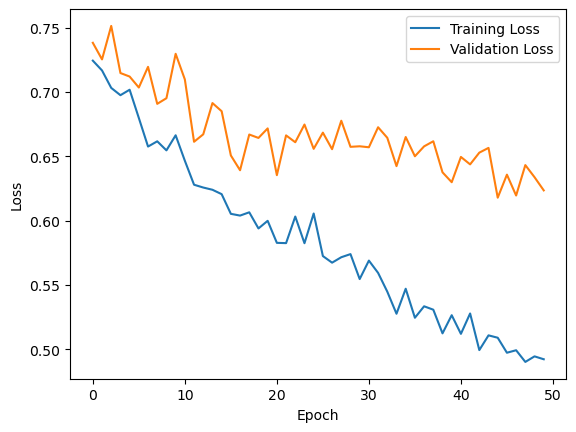

In [26]:
def evaluate_model(model, data_loader):
    model.eval()
    all_preds = []
    all_labels=[]
    with torch.no_grad():
        for inputs,labels in data_loader:
            outputs=model(inputs)
            _,preds = torch.max(outputs,1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    accuracy = accuracy_score(all_labels,all_preds)
    precision = precision_score(all_labels,all_preds,average='weighted')
    recall = recall_score(all_labels,all_preds,average='weighted')
    f1=f1_score(all_labels,all_preds,average='weighted')
    print(f'Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1:.4f}')

evaluate_model(model,test_loader)
plt.plot(train_losses, label='Training Loss')
plt.plot(valid_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

torch.save(model.state_dict(), 'binary_classification_model.pth')

## Loading trained Model and making predictions

In [27]:
model = SimpleNN()

model.load_state_dict(torch.load('binary_classification_model.pth'))
model.eval()

C:\Users\Moonwalking\AppData\Local\Temp\ipykernel_12832\947667547.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('binary_classification

SimpleNN(
  (fc1): Linear(in_features=196608, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=2, bias=True)
  (softmax): Softmax(dim=1)
)

In [28]:
image_path='test.jpg'
image=Image.open(image_path)

input_tensor = transform(image).unsqueeze(0)
print(input_tensor.shape)

torch.Size([1, 3, 256, 256])


In [29]:
with torch.no_grad():
    model_output = model(input_tensor)

_,predicted_class = torch.max(model_output,1)
print(predicted_class)

tensor([1])


In [30]:
class_labels = ['daisy','dandelion']
predicted_class_label = class_labels[predicted_class.item()]
print(f'The model predicts that the image belongs to class: {predicted_class_label}')

The model predicts that the image belongs to class: dandelion


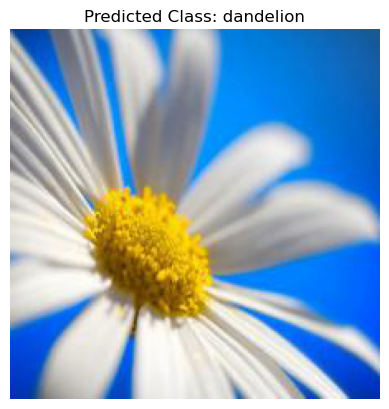

In [31]:
import numpy as np
image_array = np.array(image)
plt.imshow(image_array)
plt.title(f'Predicted Class: {predicted_class_label}')
plt.axis('off')
plt.show()

## Image Classification using ResNet-18 and Pytorch

In [32]:
data_transforms = {
    'train':transforms.Compose([
        transforms.RandomResizedCrop(225),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224, 0.225])
    ]),
    'val':transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
    ]),
}

In [37]:
from torchvision import datasets
import os
data_dir='dataset_for_pytorch'

image_datasets = {x:datasets.ImageFolder(os.path.join(data_dir,x),data_transforms[x])for x in ['train','val']}

In [39]:
dataloaders = {x:torch.utils.data.DataLoader(image_datasets[x],batch_size=4,shuffle=True,num_workers=4) for x in ['train','val']}
dataset_sizes = {x:len(image_datasets[x]) for x in ['train','val']}

class_names=image_datasets['train'].classes
class_names

['daisy', 'dandelion']

In [41]:
from torchvision import models
model = models.resnet18(pretrained=True)


for name, param in model.named_parameters():
    if "fc" in name:  
        param.requires_grad = True
    else:
        param.requires_grad = False

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9) 


device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

C:\Users\Moonwalking\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Moonwalking\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Moonwalking/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████████████████████████████████████████████████████████████████████████| 44.7M/44.7M [02:09<00:00, 361kB/s]


In [42]:
num_epochs = 10
for epoch in range(num_epochs):
    for phase in ['train', 'val']:
        if phase == 'train':
            model.train()
        else:
            model.eval()

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders[phase]:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = running_corrects.double() / dataset_sizes[phase]

        print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

print("Training complete!")

train Loss: 0.5999 Acc: 0.7575
val Loss: 0.2461 Acc: 0.9093
train Loss: 0.5531 Acc: 0.7727
val Loss: 0.3001 Acc: 0.8901
train Loss: 0.5154 Acc: 0.7895
val Loss: 0.1925 Acc: 0.9313
train Loss: 0.5126 Acc: 0.7892
val Loss: 0.1771 Acc: 0.9396
train Loss: 0.5354 Acc: 0.7903
val Loss: 0.3929 Acc: 0.8791
train Loss: 0.5506 Acc: 0.7892
val Loss: 0.3512 Acc: 0.8626
train Loss: 0.4996 Acc: 0.8008
val Loss: 0.1995 Acc: 0.9451
train Loss: 0.5019 Acc: 0.8009
val Loss: 0.1764 Acc: 0.9478
train Loss: 0.5520 Acc: 0.7835
val Loss: 0.1916 Acc: 0.9368
train Loss: 0.4903 Acc: 0.7980
val Loss: 0.1532 Acc: 0.9478
Training complete!


In [43]:
torch.save(model.state_dict(), 'flower_classification_model.pth')

In [44]:
model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, 1000)  
model.load_state_dict(torch.load('flower_classification_model.pth'))
model.eval()
new_model = models.resnet18(pretrained=True)
new_model.fc = nn.Linear(new_model.fc.in_features, 2)
new_model.fc.weight.data = model.fc.weight.data[0:2] 
new_model.fc.bias.data = model.fc.bias.data[0:2]

C:\Users\Moonwalking\AppData\Local\Temp\ipykernel_12832\865303949.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('flower_classification

In [45]:
image_path = 'test.jpg'  
image = Image.open(image_path)
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
input_tensor = preprocess(image)
input_batch = input_tensor.unsqueeze(0)  

In [46]:
with torch.no_grad():
    output = model(input_batch)
_, predicted_class = output.max(1)
class_names = ['daisy', 'dandelion']
predicted_class_name = class_names[predicted_class.item()]
print(f'The predicted class is: {predicted_class_name}')

The predicted class is: daisy


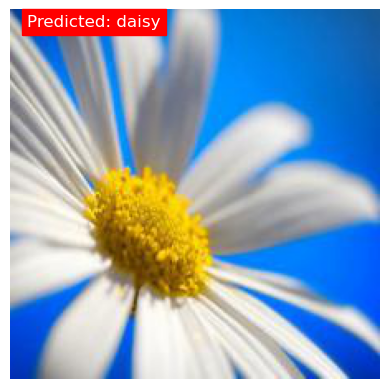

In [47]:
image = np.array(image)
plt.imshow(image)
plt.axis('off')
plt.text(10, 10, f'Predicted: {predicted_class_name}', fontsize=12, color='white', backgroundcolor='red')
plt.show()